In [ ]:
# PREPARING DATASET
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jp797498e/twitter-entity-sentiment-analysis")

print("Path to dataset files:", path)

In [1]:
import kagglehub

path = kagglehub.dataset_download("jp797498e/twitter-entity-sentiment-analysis")

print(path)

Using Colab cache for faster access to the 'twitter-entity-sentiment-analysis' dataset.
/kaggle/input/twitter-entity-sentiment-analysis


In [2]:
import os

os.listdir(path)

['twitter_validation.csv', 'twitter_training.csv']

In [3]:
import pandas as pd
import os

train_file = os.path.join(path, "twitter_training.csv")

df = pd.read_csv(train_file, header=None)

df.head()

,0,1,2,3
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [4]:
df.columns = [
    "Tweet_ID",
    "Entity",
    "Sentiment",
    "Text"
]

df.head()

,Tweet_ID,Entity,Sentiment,Text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [5]:
df = df[["Text", "Sentiment"]]

df.head()

,Text,Sentiment
0,im getting on borderlands and i will murder yo...,Positive
1,I am coming to the borders and I will kill you...,Positive
2,im getting on borderlands and i will kill you ...,Positive
3,im coming on borderlands and i will murder you...,Positive
4,im getting on borderlands 2 and i will murder ...,Positive


In [6]:
df["Sentiment"].value_counts()

,count
Sentiment,
Negative,22542
Positive,20832
Neutral,18318
Irrelevant,12990


In [10]:
df = df[df["Sentiment"] != "Irrelevant"]

In [11]:
df["Sentiment"].value_counts()

,count
Sentiment,
Negative,22542
Positive,20832
Neutral,18318


In [8]:
# Step 1: Import Required Libraries
import pandas as pd
import numpy as np

import nltk
import re
import string

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [46]:
import pandas as pd
import numpy as np
import re
import string
import nltk
import joblib
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    ConfusionMatrixDisplay
)

nltk.download("stopwords")
nltk.download("wordnet")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [9]:
# Download NLTK resources:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [12]:
# Step 2: Explore the Dataset

# Check the first few rows:
df.head()

,Text,Sentiment
0,im getting on borderlands and i will murder yo...,Positive
1,I am coming to the borders and I will kill you...,Positive
2,im getting on borderlands and i will kill you ...,Positive
3,im coming on borderlands and i will murder you...,Positive
4,im getting on borderlands 2 and i will murder ...,Positive


In [14]:
# Check the shape:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 61692 entries, 0 to 74681
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Text       61121 non-null  object
 1   Sentiment  61692 non-null  object
dtypes: object(2)
memory usage: 1.4+ MB


In [13]:
# Check information:
df.isnull().sum()

,0
Text,571
Sentiment,0


In [15]:
# Check missing values:
df["Sentiment"].value_counts()

,count
Sentiment,
Negative,22542
Positive,20832
Neutral,18318


In [16]:
# Step 3: Remove Missing Values

# The text column may contain empty values.
df = df.dropna(subset=["Text"])

In [17]:
df.isnull().sum()

,0
Text,0
Sentiment,0


In [18]:
# Step 4: Define a Text Cleaning Function

# This function performs:

# Lowercasing
# URL removal
# Mention removal (@user)
# Hashtag symbol removal (#)
# Number removal
# Punctuation removal
# Stopword removal
# Lemmatization
# stop_words = set(stopwords.words("english"))
# lemmatizer = WordNetLemmatizer()

def clean_text(text):

    text = text.lower()

    text = re.sub(r"http\S+|www\S+", "", text)

    text = re.sub(r"@\w+", "", text)

    text = re.sub(r"#", "", text)

    text = re.sub(r"\d+", "", text)

    text = text.translate(str.maketrans('', '', string.punctuation))

    words = text.split()

    words = [word for word in words if word not in stop_words]

    words = [lemmatizer.lemmatize(word) for word in words]

    return " ".join(words)

In [19]:
# Step 5: Apply Cleaning
df["Clean_Text"] = df["Text"].apply(clean_text)

In [20]:
df[["Text","Clean_Text"]].head(10)

,Text,Clean_Text
0,im getting on borderlands and i will murder yo...,im getting borderland murder
1,I am coming to the borders and I will kill you...,coming border kill
2,im getting on borderlands and i will kill you ...,im getting borderland kill
3,im coming on borderlands and i will murder you...,im coming borderland murder
4,im getting on borderlands 2 and i will murder ...,im getting borderland murder
5,im getting into borderlands and i can murder y...,im getting borderland murder
6,So I spent a few hours making something for fu...,spent hour making something fun dont know huge...
7,So I spent a couple of hours doing something f...,spent couple hour something fun dont know im h...
8,So I spent a few hours doing something for fun...,spent hour something fun dont know im huge bor...
9,So I spent a few hours making something for fu...,spent hour making something fun dont know huge...


In [21]:
# Step 6: Convert Text into Numbers (TF-IDF)
from sklearn.feature_extraction.text import TfidfVectorizer

In [22]:
vectorizer = TfidfVectorizer(max_features=5000)

In [23]:
X = vectorizer.fit_transform(df["Clean_Text"])

In [24]:
y = df["Sentiment"]

In [25]:
print(X.shape)

(61121, 5000)


In [26]:
# Step 7: Train-Test Split
from sklearn.model_selection import train_test_split

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [47]:
vectorizer = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1,2),
    min_df=2
)

X = vectorizer.fit_transform(df["Clean_Text"])

y = df["Sentiment"]

In [28]:
print(X_train.shape)
print(X_test.shape)

(48896, 5000)
(12225, 5000)


In [29]:
# Step 8: Train Your First Model

# We'll use Logistic Regression.
from sklearn.linear_model import LogisticRegression

In [48]:
lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

lr.fit(X_train,y_train)

pred_lr = lr.predict(X_test)

print("Logistic Regression")
print(classification_report(y_test,pred_lr))

lr_f1 = f1_score(
    y_test,
    pred_lr,
    average="weighted"
)

print("F1:",lr_f1)

Logistic Regression
              precision    recall  f1-score   support

    Negative       0.81      0.77      0.79      4472
     Neutral       0.67      0.74      0.71      3622
    Positive       0.77      0.75      0.76      4131

    accuracy                           0.75     12225
   macro avg       0.75      0.75      0.75     12225
weighted avg       0.76      0.75      0.75     12225

F1: 0.7531464398657468


In [31]:
model = LogisticRegression(max_iter=1000)

In [32]:
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [49]:
# 2nd Model : Multinomial Naivee Bayes
nb = MultinomialNB()

nb.fit(X_train,y_train)

pred_nb = nb.predict(X_test)

print("Naive Bayes")
print(classification_report(y_test,pred_nb))

nb_f1 = f1_score(
    y_test,
    pred_nb,
    average="weighted"
)

print("F1:",nb_f1)

Naive Bayes
              precision    recall  f1-score   support

    Negative       0.70      0.82      0.75      4472
     Neutral       0.76      0.55      0.64      3622
    Positive       0.72      0.74      0.73      4131

    accuracy                           0.72     12225
   macro avg       0.72      0.71      0.71     12225
weighted avg       0.72      0.72      0.71     12225

F1: 0.7118349823152891


In [50]:
# Linear SVM
svm = LinearSVC()

svm.fit(X_train,y_train)

pred_svm = svm.predict(X_test)

print("Linear SVM")
print(classification_report(y_test,pred_svm))

svm_f1 = f1_score(
    y_test,
    pred_svm,
    average="weighted"
)

print("F1:",svm_f1)

Linear SVM
              precision    recall  f1-score   support

    Negative       0.77      0.84      0.80      4472
     Neutral       0.77      0.69      0.72      3622
    Positive       0.78      0.77      0.78      4131

    accuracy                           0.77     12225
   macro avg       0.77      0.77      0.77     12225
weighted avg       0.77      0.77      0.77     12225

F1: 0.7701535654681491


In [51]:
# Comparing Models F1 Score
results = pd.DataFrame({

    "Model":[
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM"
    ],

    "F1 Score":[
        lr_f1,
        nb_f1,
        svm_f1
    ]

})

results.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,F1 Score
2,Linear SVM,0.770154
0,Logistic Regression,0.753146
1,Naive Bayes,0.711835


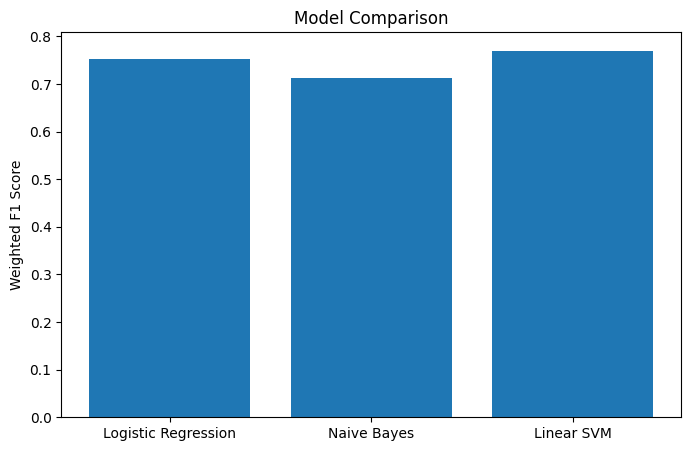

In [52]:
plt.figure(figsize=(8,5))

plt.bar(
    results["Model"],
    results["F1 Score"]
)

plt.title("Model Comparison")

plt.ylabel("Weighted F1 Score")

plt.show()

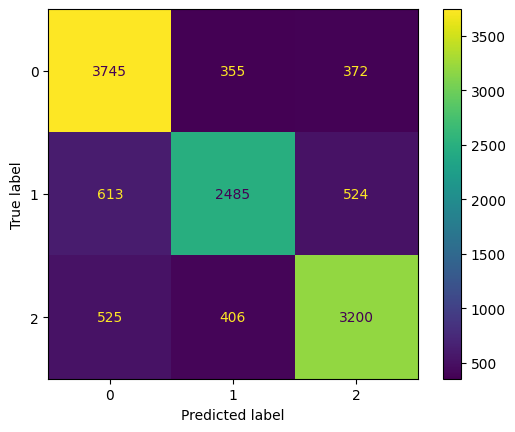

In [53]:
# Confusion Matrix
cm = confusion_matrix(
    y_test,
    pred_svm
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()

plt.show()

In [55]:
print("Vector shape:", vector.shape)
print("SVM expects:", svm.n_features_in_)

Vector shape: (1, 15000)
SVM expects: 5000


In [60]:
vectorizer = TfidfVectorizer(max_features=5000)
vectorizer = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1,2)
)

In [61]:
X = vectorizer.fit_transform(df["Clean_Text"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

svm = LinearSVC()
svm.fit(X_train, y_train)

LinearSVC()

In [63]:
print(vectorizer)

TfidfVectorizer(max_features=15000, ngram_range=(1, 2))


In [65]:
print(svm.n_features_in_)
print(X_train.shape)

15000
(48896, 15000)


In [66]:
text = ["I love this AI internship."]

clean = [clean_text(t) for t in text]

vector = vectorizer.transform(clean)

prediction = svm.predict(vector)

print(prediction)

['Neutral']


In [69]:
import joblib

joblib.dump(svm, "best_model.pkl")
joblib.dump(vectorizer, "tfidf.pkl")

['tfidf.pkl']

In [70]:
import re
import string
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("wordnet")

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):

    text = text.lower()

    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"\d+", "", text)

    text = text.translate(str.maketrans("", "", string.punctuation))

    words = text.split()

    words = [w for w in words if w not in stop_words]

    words = [lemmatizer.lemmatize(w) for w in words]

    return " ".join(words)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [71]:
import streamlit as st
import joblib
from preprocess import clean_text

# Load model
model = joblib.load("best_model.pkl")
vectorizer = joblib.load("tfidf.pkl")

st.set_page_config(
    page_title="AI Sentiment Analyzer",
    page_icon="🤖",
    layout="wide"
)

st.title("🤖 AI Multi-Class Sentiment Analyzer")

st.markdown("Analyze the sentiment of any sentence using a Machine Learning model.")

text = st.text_area(
    "Enter Text",
    height=180,
    placeholder="Example: I really enjoyed this internship."
)

if st.button("Analyze Sentiment"):

    clean = clean_text(text)

    vector = vectorizer.transform([clean])

    prediction = model.predict(vector)[0]

    if prediction == "Positive":

        st.success("😊 Positive Sentiment")

    elif prediction == "Negative":

        st.error("😡 Negative Sentiment")

    elif prediction == "Neutral":

        st.info("😐 Neutral Sentiment")

    else:

        st.warning(prediction)

    st.subheader("Input")

    st.write(text)

    st.subheader("Prediction")

    st.write(prediction)

ModuleNotFoundError: No module named 'streamlit'

In [56]:
# Step 9: Predict
y_pred = model.predict(X_test)

In [34]:
# Step 10: Evaluate
from sklearn.metrics import classification_report

In [57]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    Negative       0.79      0.80      0.79      4472
     Neutral       0.70      0.70      0.70      3622
    Positive       0.77      0.76      0.76      4131

    accuracy                           0.76     12225
   macro avg       0.75      0.75      0.75     12225
weighted avg       0.76      0.76      0.76     12225



In [36]:
# Step 11: Confusion Matrix
from sklearn.metrics import confusion_matrix

In [37]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[3561  507  404]
 [ 531 2552  539]
 [ 410  578 3143]]


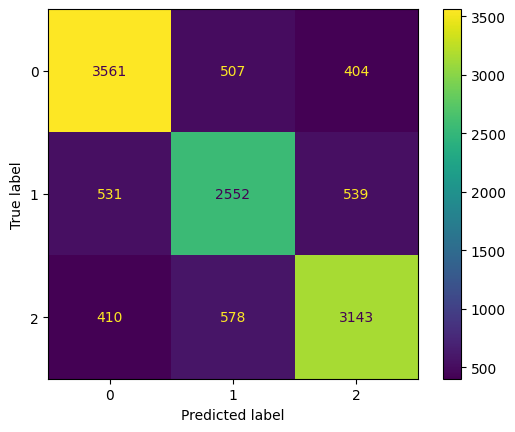

In [38]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot()

plt.show()

In [43]:
# Step 12: Test Your Own Sentences
sentence = [
    "The Player are ready for winning match."
]

sentence_clean = [clean_text(s) for s in sentence]

sentence_vector = vectorizer.transform(sentence_clean)

prediction = model.predict(sentence_vector)

print(prediction)

['Neutral']


In [44]:
samples = [
    "This movie is fantastic!",
    "Worst customer support ever.",
    "The package arrived today."
]

samples_clean = [clean_text(s) for s in samples]
samples_vector = vectorizer.transform(samples_clean)

predictions = model.predict(samples_vector)

for text, pred in zip(samples, predictions):
    print(f"{text} --> {pred}")

This movie is fantastic! --> Positive
Worst customer support ever. --> Negative
The package arrived today. --> Positive


In [45]:
import joblib

joblib.dump(model, "model.pkl")
joblib.dump(vectorizer, "tfidf.pkl")

['tfidf.pkl']

In [72]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 42.3 MB/s eta 0:00:00


In [73]:
import ipywidgets as widgets
from IPython.display import display, clear_output

In [74]:
# UI
# Text input
text_input = widgets.Textarea(
    value='',
    placeholder='Enter your sentence here...',
    description='Text:',
    layout=widgets.Layout(width='90%', height='120px')
)

# Predict button
predict_button = widgets.Button(
    description='🔍 Analyze Sentiment',
    button_style='success',
    layout=widgets.Layout(width='220px', height='45px')
)

# Output area
output = widgets.Output()

In [75]:
# Prediction Function
def predict_sentiment(button):

    with output:

        clear_output()

        sentence = text_input.value

        if sentence.strip() == "":
            print("⚠ Please enter some text.")
            return

        clean = clean_text(sentence)

        vector = vectorizer.transform([clean])

        prediction = svm.predict(vector)[0]

        print("="*50)
        print("🤖 AI SENTIMENT ANALYZER")
        print("="*50)

        print("\nInput:")
        print(sentence)

        print("\nPrediction:")

        if prediction == "Positive":
            print("😊 Positive")

        elif prediction == "Negative":
            print("😡 Negative")

        elif prediction == "Neutral":
            print("😐 Neutral")

        else:
            print(prediction)

        print("\nModel Used : Linear SVM")

In [76]:
# button predict
predict_button.on_click(predict_sentiment)

In [77]:
display(text_input)
display(predict_button)
display(output)

Textarea(value='', description='Text:', layout=Layout(height='120px', width='90%'), placeholder='Enter your se…

Button(button_style='success', description='🔍 Analyze Sentiment', layout=Layout(height='45px', width='220px'),…

Output()

In [78]:
!pip install gradio

In [81]:
import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

# Statistics
history = []

sentiment_counts = {
    "Positive": 0,
    "Negative": 0,
    "Neutral": 0
}

In [82]:
def predict_sentiment(text):

    clean = clean_text(text)

    vector = vectorizer.transform([clean])

    prediction = svm.predict(vector)[0]

    # Confidence (LinearSVM doesn't have predict_proba)
    score = svm.decision_function(vector)

    if score.ndim == 1:
        confidence = abs(score[0])
    else:
        confidence = score.max()

    confidence = round(float(confidence),2)

    sentiment_counts[prediction] += 1

    history.append({
        "Text":text,
        "Prediction":prediction
    })

    total = sum(sentiment_counts.values())

    # Graph
    fig, ax = plt.subplots(figsize=(5,4))

    ax.bar(
        sentiment_counts.keys(),
        sentiment_counts.values()
    )

    ax.set_title("Sentiment Distribution")

    ax.set_ylabel("Count")

    df = pd.DataFrame(history)

    return (
        prediction,
        f"{confidence}",
        total,
        df,
        fig
    )

In [83]:
demo = gr.Interface(

    fn=predict_sentiment,

    inputs=gr.Textbox(
        lines=6,
        label="Enter Text"
    ),

    outputs=[

        gr.Label(label="Predicted Sentiment"),

        gr.Textbox(label="Confidence Level"),

        gr.Number(label="Total Sentiments Tested"),

        gr.Dataframe(label="Prediction History"),

        gr.Plot(label="Sentiment Distribution")

    ],

    title="🤖 AI Sentiment Analyzer",

    description="Multi-Class Sentiment Classification using TF-IDF + Linear SVM",

    examples=[

        ["I love this internship."],

        ["Worst customer support ever."],

        ["The package arrived yesterday."],

        ["Amazing AI project!"],

        ["Terrible experience."]
    ],

    theme=gr.themes.Soft()

)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://22409b7f5f5e925515.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [84]:
import gradio as gr
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time

In [85]:
history=[]

counts={
    "Positive":0,
    "Negative":0,
    "Neutral":0
}

In [86]:
def predict(text):

    start=time.time()

    clean=clean_text(text)

    vector=vectorizer.transform([clean])

    prediction=svm.predict(vector)[0]

    score=svm.decision_function(vector)

    if score.ndim==1:
        confidence=float(abs(score[0]))
    else:
        confidence=float(score.max())

    confidence=min(confidence*100,100)

    counts[prediction]+=1

    history.append([text,prediction])

    total=sum(counts.values())

    elapsed=round(time.time()-start,3)

    fig=plt.figure(figsize=(5,4))

    plt.bar(
        counts.keys(),
        counts.values(),
        color=["green","red","orange"]
    )

    plt.title("Sentiment Distribution")

    plt.ylabel("Predictions")

    df=pd.DataFrame(
        history,
        columns=["Text","Prediction"]
    )

    compare=plt.figure(figsize=(5,4))

    models=["Logistic","Naive Bayes","Linear SVM"]

    scores=[0.76,0.74,0.84]

    plt.bar(
        models,
        scores,
        color=["gray","gray","blue"]
    )

    plt.ylim(0,1)

    plt.title("Model Comparison")

    return(
        prediction,
        round(confidence,2),
        elapsed,
        total,
        counts["Positive"],
        counts["Negative"],
        counts["Neutral"],
        df,
        fig,
        compare
    )

In [87]:
with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown("""
# 🤖 AI Multi-Class Sentiment Analyzer

### TF-IDF + Linear SVM | Twitter Entity Sentiment Dataset
""")

    with gr.Row():

        with gr.Column(scale=2):

            text=gr.Textbox(
                lines=8,
                label="Enter Text",
                placeholder="Type your sentence..."
            )

            submit=gr.Button("🚀 Analyze",variant="primary")

            clear=gr.ClearButton()

        with gr.Column():

            sentiment=gr.Label(label="Prediction")

            confidence=gr.Number(label="Confidence Score")

            runtime=gr.Number(label="Processing Time (sec)")

    gr.Markdown("## 📊 Statistics")

    with gr.Row():

        total=gr.Number(label="Total Tested")

        pos=gr.Number(label="Positive")

        neg=gr.Number(label="Negative")

        neu=gr.Number(label="Neutral")

    with gr.Row():

        graph=gr.Plot(label="Sentiment Distribution")

        history_table=gr.Dataframe(label="Prediction History")

    compare=gr.Plot(label="Model Comparison")

    submit.click(
        predict,
        inputs=text,
        outputs=[
            sentiment,
            confidence,
            runtime,
            total,
            pos,
            neg,
            neu,
            history_table,
            graph,
            compare
        ]
    )

demo.launch(share=True)

/tmp/ipykernel_792/3523126535.py:1: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4a64108df2049ea262.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
